# 3. CPTAC validation results

Consolidated replacement for `3. results_tmt.ipynb`, `3. results_labelfree.ipynb`, and `3. results_itraq.ipynb`.

This notebook checks the saved best-model result files, evaluates the same coefficient-dictionary models on TMT, LabelFree, and iTRAQ validation data, compares all tissues versus a filtered-tissue view, and produces compact summary plots.

In [1]:
# >>> pRNA figure routing (added by the pRNA update; keep as the first code cell)
# Every figure is shown inline. Every file written with savefig (png, pdf, svg) is redirected to
# figures_pdf/<notebook name>/ next to this notebook; sub-folders of the original path are preserved.
import os as _fig_os
from pathlib import Path as _FigPath
import matplotlib as _fig_mpl
import matplotlib.pyplot as _fig_plt
from matplotlib.figure import Figure as _FigFigure

NOTEBOOK_NAME = "3.results_cptac_loo"
FIG_DIR = (_FigPath.cwd() / "figures_pdf" / NOTEBOOK_NAME).resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _route_figure_path(fname):
    p = _FigPath(_fig_os.fspath(fname))
    full = p if p.is_absolute() else (_FigPath.cwd() / p)
    try:
        full.resolve().relative_to(FIG_DIR)
        return fname                                  # already inside this notebook's figure folder
    except ValueError:
        pass
    try:
        rel = _FigPath(_fig_os.path.relpath(full.resolve(), _FigPath.cwd()))
    except ValueError:                                # e.g. another drive on Windows
        rel = _FigPath(p.name)
    parts = [x for x in rel.parts if x not in ("..", ".", "figures_pdf", NOTEBOOK_NAME)]
    target = FIG_DIR.joinpath(*parts) if parts else FIG_DIR / p.name
    target.parent.mkdir(parents=True, exist_ok=True)
    return target


if not getattr(_FigFigure.savefig, "_prna_routed", False):
    _fig_orig_savefig = _FigFigure.savefig

    def _fig_routed_savefig(self, fname, *args, **kwargs):
        if isinstance(fname, (str, bytes, _FigPath)) or hasattr(fname, "__fspath__"):
            fname = _route_figure_path(fname)
        return _fig_orig_savefig(self, fname, *args, **kwargs)

    _fig_routed_savefig._prna_routed = True
    _FigFigure.savefig = _fig_routed_savefig

    _fig_orig_close = _fig_plt.close

    def _fig_close_and_show(fig=None):
        """Display figures that are closed before Jupyter could render them, then close."""
        import inspect as _fig_inspect
        _caller = _fig_inspect.currentframe().f_back
        _caller_mod = (_caller.f_globals.get("__name__", "") if _caller is not None else "")
        if _caller_mod.startswith(("matplotlib", "ipykernel")):   # backend housekeeping, not user code
            return _fig_orig_close(fig)
        if "inline" in str(_fig_mpl.get_backend()).lower():
            from IPython.display import display as _fig_display
            open_nums = set(_fig_plt.get_fignums())
            if fig is None:
                figs = [_fig_plt.gcf()] if open_nums else []
            elif isinstance(fig, str) and fig == "all":
                figs = [_fig_plt.figure(n) for n in sorted(open_nums)]
            elif isinstance(fig, _FigFigure):
                figs = [fig] if getattr(fig, "number", None) in open_nums else []
            elif isinstance(fig, int):
                figs = [_fig_plt.figure(fig)] if fig in open_nums else []
            else:
                figs = []
            for _f in figs:
                if not getattr(_f, "_prna_displayed", False):
                    _f._prna_displayed = True
                    _fig_display(_f)
        return _fig_orig_close(fig)

    _fig_plt.close = _fig_close_and_show

    _fig_orig_show = _fig_plt.show

    def _fig_show_and_mark(*args, **kwargs):
        for _n in _fig_plt.get_fignums():                    # shown now -> never re-displayed on close
            _fig_plt.figure(_n)._prna_displayed = True
        return _fig_orig_show(*args, **kwargs)

    _fig_plt.show = _fig_show_and_mark

print("Figures are saved to", FIG_DIR)

Figures are saved to C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\notebooks\figures_pdf\3.results_cptac_loo


In [2]:
from pathlib import Path
import sys

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import src.utils_val as uv
from src.utils_val import (
    load_best_result_tables,
    load_batch_result_tables,
    compare_model_result_tables,
    evaluate_cptac_validation_datasets,
    summarize_cptac_results,
    plot_cptac_summary,
    plot_cptac_metric_distributions,
    plot_cptac_tissue_mse,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 180, "axes.titleweight": "bold"})

## 1. Configuration

Paths match the original notebooks. `results_val` holds the trained coefficient models; `val_data` holds normalized validation matrices generated by notebook 2.

In [3]:
RESULTS_DIR = Path("../data/loo/results_zscore")
VAL_DATA_DIR = Path("../data/val_data")
OUTPUT_DIR = Path("../data/loo/results_zscore/plots_cptac_unified")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_CONFIGS = {
    "TMT": {
        "rna_path": VAL_DATA_DIR / "TMT_transcriptomics.joblib",
        "prot_path": VAL_DATA_DIR / "TMT_proteomics.joblib",
    },
    "LabelFree": {
        "rna_path": VAL_DATA_DIR / "LabelFree_transcriptomics.joblib",
        "prot_path": VAL_DATA_DIR / "LabelFree_proteomics.joblib",
    },
    "iTRAQ": {
        "rna_path": VAL_DATA_DIR / "iTRAQ_transcriptomics.joblib",
        "prot_path": VAL_DATA_DIR / "iTRAQ_proteomics.joblib",
    },
}

# Same filtered-tissue list used in the original split notebooks.
EXCLUDED_TISSUES = ["RENAL_2019", "HEADNECK_2021", "PANCREA2021"]

# Original notebook skipped models with missing RNA features. Keep that behavior here.
IMPUTE_MISSING_FEATURES = False

print("Results directory:", RESULTS_DIR.resolve())
print("Validation data directory:", VAL_DATA_DIR.resolve())

Results directory: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\data\loo\results_zscore
Validation data directory: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\05. validation\data\val_data


## 2. Best-model and batch-file consistency check

In [4]:
best_models, best_files = load_best_result_tables(RESULTS_DIR)
batch_models, batch_files = load_batch_result_tables(RESULTS_DIR)
comparison = compare_model_result_tables(best_models, batch_models)

print(f"Best-model files: {len(best_files)}")
print(f"Batch files:      {len(batch_files)}")
print(f"Best rows:        {len(best_models):,}")
print(f"Batch rows:       {len(batch_models):,}")
display(pd.DataFrame([comparison]).drop(columns=["missing_in_batch", "missing_in_best"], errors="ignore"))

if comparison.get("missing_in_batch"):
    print("Proteins in best files but not batch files:", comparison["missing_in_batch"][:10])
if comparison.get("missing_in_best"):
    print("Proteins in batch files but not best files:", comparison["missing_in_best"][:10])

display(best_models.head())

Best-model files: 1809
Batch files:      0
Best rows:        1,809
Batch rows:       0


,can_compare,best_rows,batch_rows,message
0,False,1809,0,One or both result tables are empty.


,protein,best_sample,best_abs_error,mse_all_others,params_dict,feat_coeffs_dict,zscore_genes,zscore_mu,zscore_sigma,zscore_eps,source_file
0,A2M,UMUC3_URINARY_TRACT,0.003011,0.836941,"{'alpha': 1.0, 'l1_ratio': 0.1}","{'A1BG': 0.0, 'A2M': 0.05601153568687824, 'AAD...","['A1BG', 'A2M', 'AADAT', 'AASS', 'ABCB6', 'ABI...","[2.821546846143207, 0.8868445119261132, 2.2698...","[2.051967442561821, 1.8051704733585499, 1.2569...",1.000000e-08,A2M_best.csv
1,AARS2,SQ1_LUNG,0.000137,0.140420,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'A2M': 0.0, 'AARS2': 0.15406732440684603, 'AA...","['A2M', 'AARS2', 'AATK', 'ABCC10', 'ABCG1', 'A...","[0.8871246572874287, 3.4942220091470135, 1.098...","[1.8050580488255072, 0.6163178413829652, 1.117...",1.000000e-08,AARS2_best.csv
2,AASDHPPT,HEC59_ENDOMETRIUM,0.000364,0.273664,"{'alpha': 0.1, 'l1_ratio': 0.9}","{'A4GALT': -0.0, 'AAAS': 0.0, 'AARS2': 0.0, 'A...","['A4GALT', 'AAAS', 'AARS2', 'AASDHPPT', 'ABCB1...","[2.103931763318877, 5.69152738256317, 3.493995...","[1.5504930921286346, 0.5083307393271205, 0.616...",1.000000e-08,AASDHPPT_best.csv
3,ABCB7,SEM_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.000245,0.147214,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AASS': -0.0, 'ABCB6': -0.0, 'ABCB7': 0.22758...","['AASS', 'ABCB6', 'ABCB7', 'ABI3', 'ABL1', 'AC...","[2.029682970399025, 4.270079436520009, 4.11333...","[1.4572810773960054, 1.3446260392182268, 0.563...",1.000000e-08,ABCB7_best.csv
4,ABCD3,CAL33_UPPER_AERODIGESTIVE_TRACT,0.000973,0.202043,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AAAS': -0.0, 'AASDHPPT': -0.0118042086846440...","['AAAS', 'AASDHPPT', 'ABCC3', 'ABCC6', 'ABCD3'...","[5.692029499779636, 4.809574950496353, 3.54140...","[0.5086774092766796, 0.610410849672823, 2.4961...",1.000000e-08,ABCD3_best.csv


## 3. Evaluate all CPTAC validation datasets

Each dataset is evaluated twice: first with all tissues, then after dropping the three known high-error tissue groups used in the original notebooks.

In [5]:
cptac_results = evaluate_cptac_validation_datasets(
    DATASET_CONFIGS,
    best_models,
    excluded_tissues=EXCLUDED_TISSUES,
    impute_missing_features=IMPUTE_MISSING_FEATURES,
)

summary_df = summarize_cptac_results(cptac_results)
print("Summary rows:", len(summary_df))
display(summary_df.round(4))


Dataset: TMT
all_tissues: proteins=186, samples=1,924, mean corr=0.1659
filtered_tissues: proteins=186, samples=1,448, mean corr=0.0479

Dataset: LabelFree
all_tissues: proteins=186, samples=360, mean corr=0.0561
filtered_tissues: proteins=186, samples=360, mean corr=0.0561

Dataset: iTRAQ
all_tissues: proteins=186, samples=276, mean corr=0.0488
filtered_tissues: proteins=186, samples=276, mean corr=0.0488
Summary rows: 6


,Dataset,Scope,Samples,Proteins_evaluated,Targets_present,Mean_MSE,Median_MSE,Mean_Correlation,Median_Correlation,Mean_Cosine,Median_missing_feature_fraction
0,TMT,all_tissues,1924,186,185,10.9261,8.3108,0.1659,0.2512,0.1641,0.0025
1,TMT,filtered_tissues,1448,186,185,5.8949,3.7888,0.0479,0.0510,0.1096,0.0025
2,LabelFree,all_tissues,360,186,185,2.4180,1.1733,0.0561,0.0734,0.0621,0.0025
3,LabelFree,filtered_tissues,360,186,185,2.4180,1.1733,0.0561,0.0734,0.0621,0.0025
4,iTRAQ,all_tissues,276,186,185,0.9502,0.3589,0.0488,0.0588,0.0370,0.0025
5,iTRAQ,filtered_tissues,276,186,185,0.9502,0.3589,0.0488,0.0588,0.0370,0.0025


## 4. Feature coverage and zero inflation checks

In [6]:
coverage_rows = []
zero_rows = []
for (dataset, scope), bundle in cptac_results.items():
    cov = bundle["coverage_df"].copy()
    if len(cov):
        cov["Dataset"] = dataset
        cov["Scope"] = scope
        coverage_rows.append(cov)
    zeros = bundle["zero_stats"].copy()
    if len(zeros):
        zeros["Dataset"] = dataset
        zeros["Scope"] = scope
        zero_rows.append(zeros)

coverage_df = pd.concat(coverage_rows, ignore_index=True) if coverage_rows else pd.DataFrame()
zero_stats_df = pd.concat(zero_rows, ignore_index=True) if zero_rows else pd.DataFrame()

if len(coverage_df):
    coverage_summary = (
        coverage_df.groupby(["Dataset", "Scope"], as_index=False)
        .agg(
            models=("Protein", "nunique"),
            median_missing_fraction=("missing_fraction", "median"),
            max_missing_fraction=("missing_fraction", "max"),
        )
    )
    display(coverage_summary.round(4))

if len(zero_stats_df):
    print("Highest RNA zero percentages by dataset/scope")
    display(
        zero_stats_df.sort_values("percent_zeros", ascending=False)
        .groupby(["Dataset", "Scope"], as_index=False)
        .head(5)
        .round(3)
    )

,Dataset,Scope,models,median_missing_fraction,max_missing_fraction
0,LabelFree,all_tissues,1809,0.0025,0.0201
1,LabelFree,filtered_tissues,1809,0.0025,0.0201
2,TMT,all_tissues,1809,0.0025,0.0201
3,TMT,filtered_tissues,1809,0.0025,0.0201
4,iTRAQ,all_tissues,1809,0.0025,0.0201
5,iTRAQ,filtered_tissues,1809,0.0025,0.0201


Highest RNA zero percentages by dataset/scope


,Tissue,percent_zeros,samples,Dataset,Scope
0,BRAIN_2021,0.0,108,TMT,all_tissues
19,LUNG_VAL,0.0,211,TMT,filtered_tissues
21,BRAIN,0.0,71,LabelFree,all_tissues
22,COLON,0.0,86,LabelFree,all_tissues
23,LIVER,0.0,62,LabelFree,all_tissues
24,LUNG,0.0,76,LabelFree,all_tissues
25,PROSTATE,0.0,65,LabelFree,all_tissues
26,BRAIN,0.0,71,LabelFree,filtered_tissues
27,COLON,0.0,86,LabelFree,filtered_tissues
28,LIVER,0.0,62,LabelFree,filtered_tissues


## 5. Compact performance plots

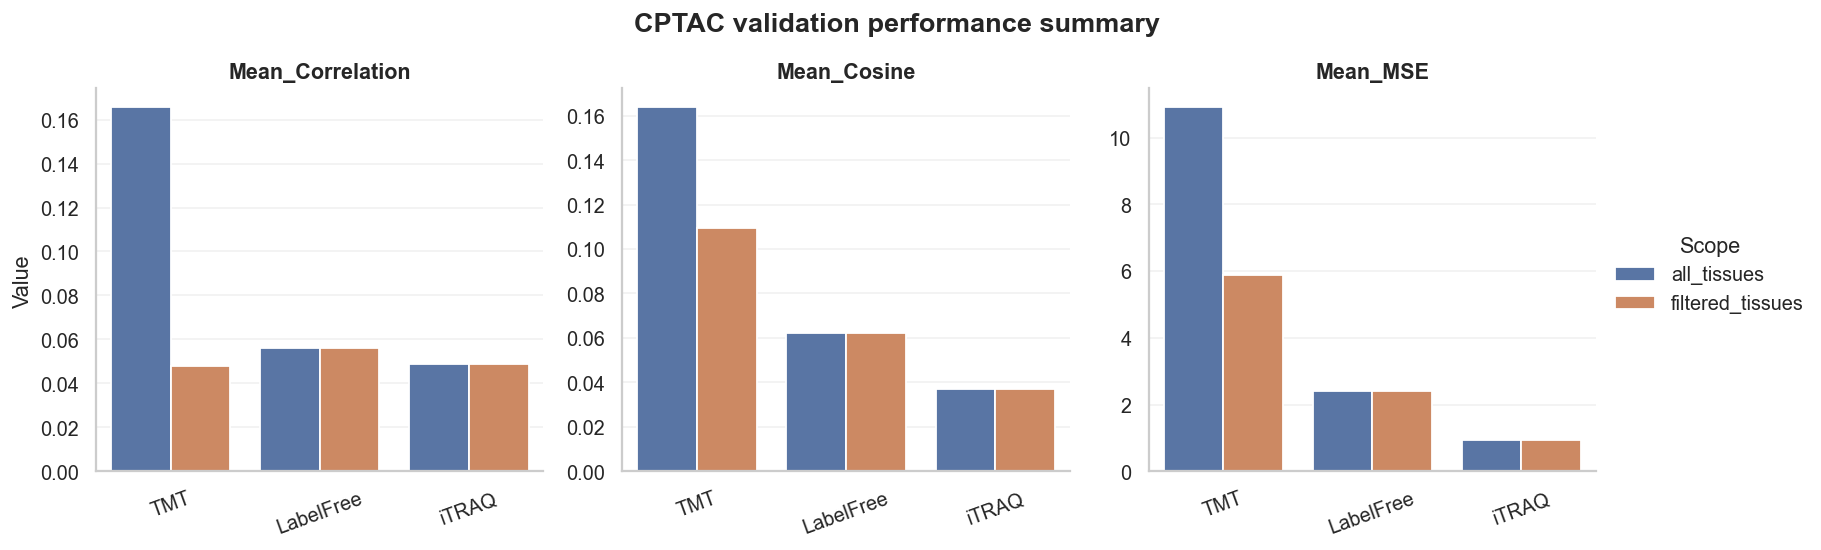

In [7]:
fig = plot_cptac_summary(summary_df)
if fig is not None:
    fig.savefig(OUTPUT_DIR / "cptac_summary.png", bbox_inches="tight")

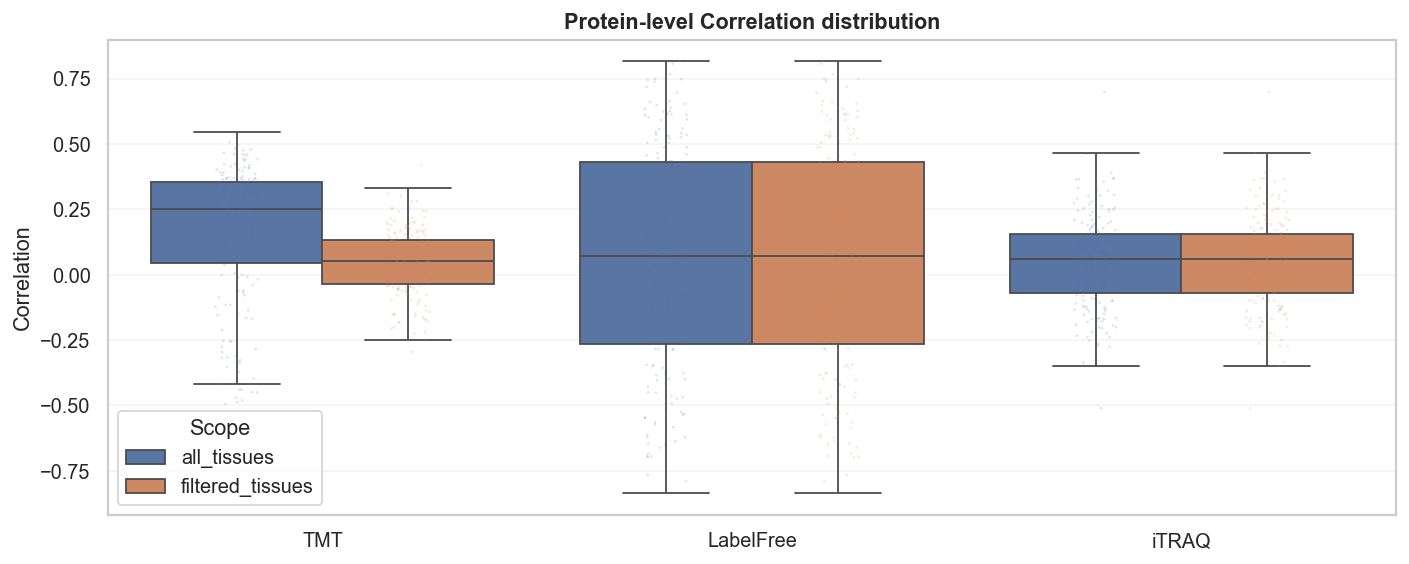

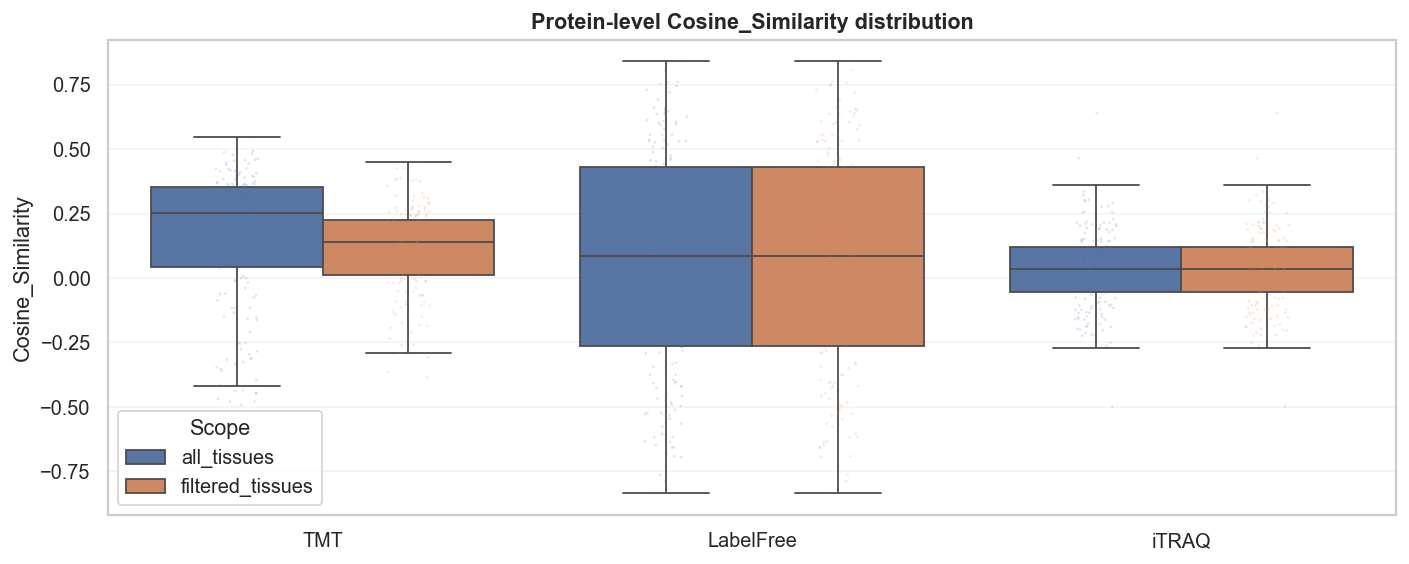

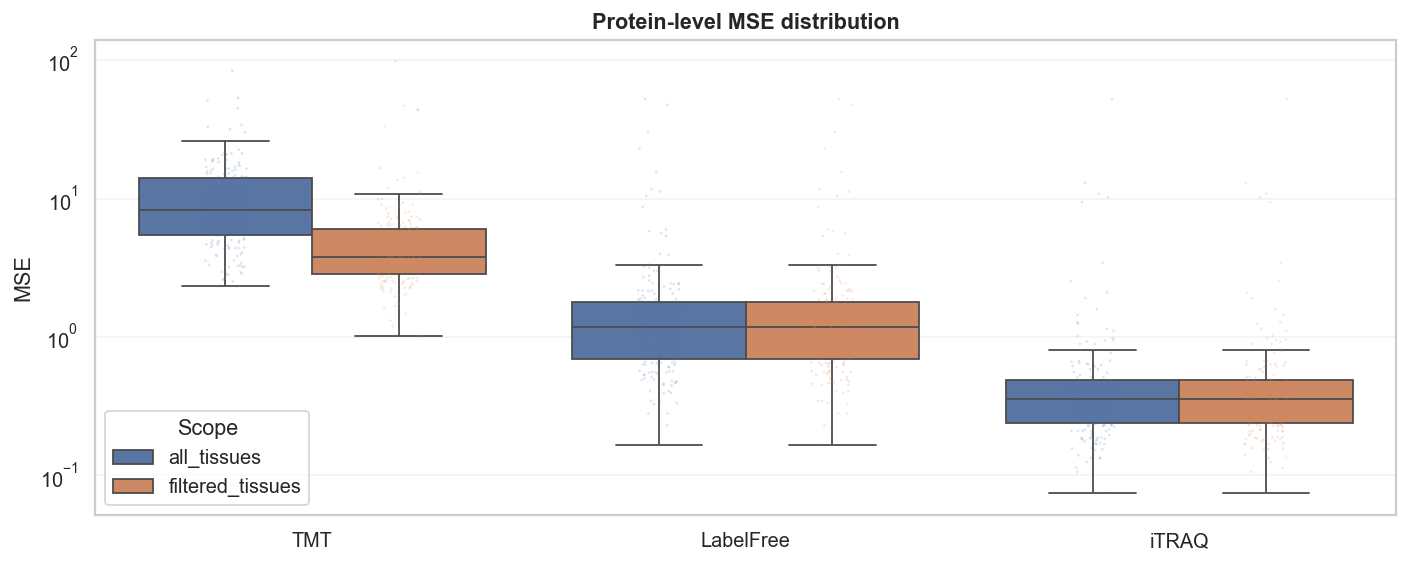

In [8]:
long_results = []
for (dataset, scope), bundle in cptac_results.items():
    df = bundle["results_df"].copy()
    if len(df):
        df["Dataset"] = dataset
        df["Scope"] = scope
        long_results.append(df)

long_results_df = pd.concat(long_results, ignore_index=True) if long_results else pd.DataFrame()
plot_cptac_metric_distributions(long_results_df)

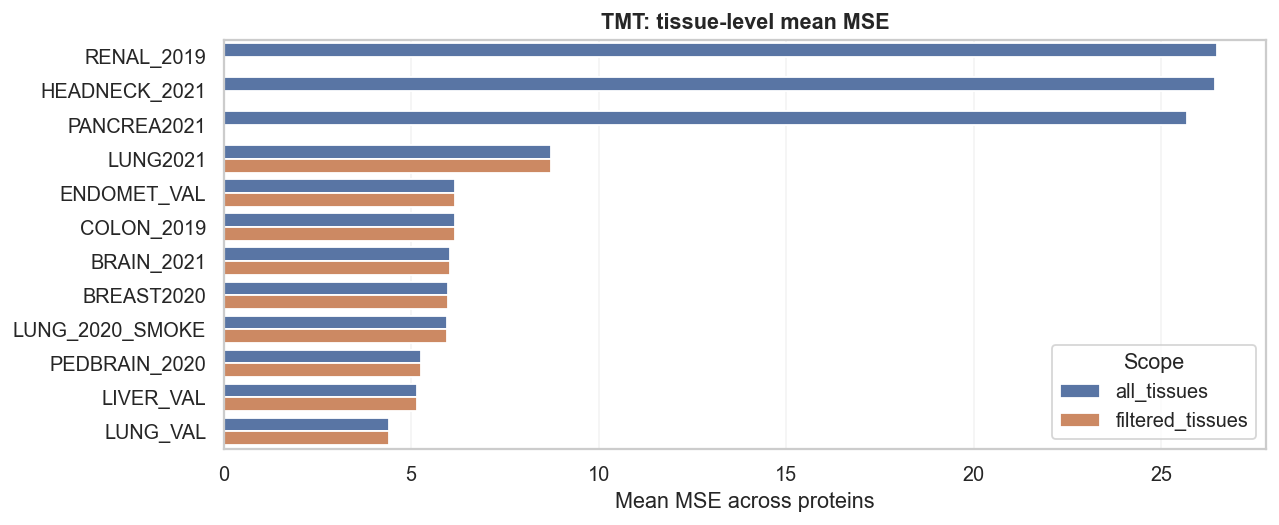

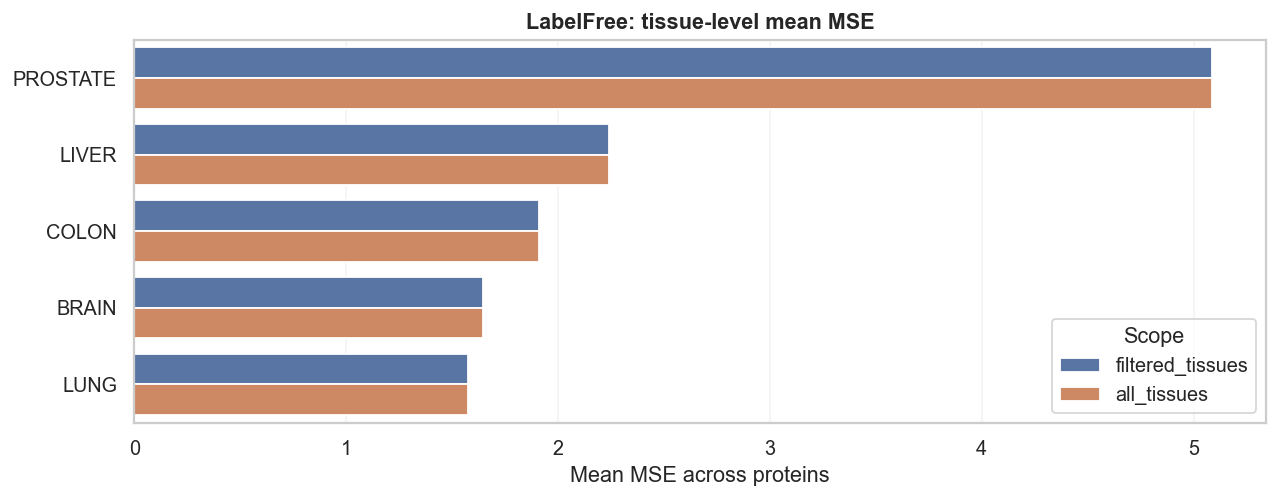

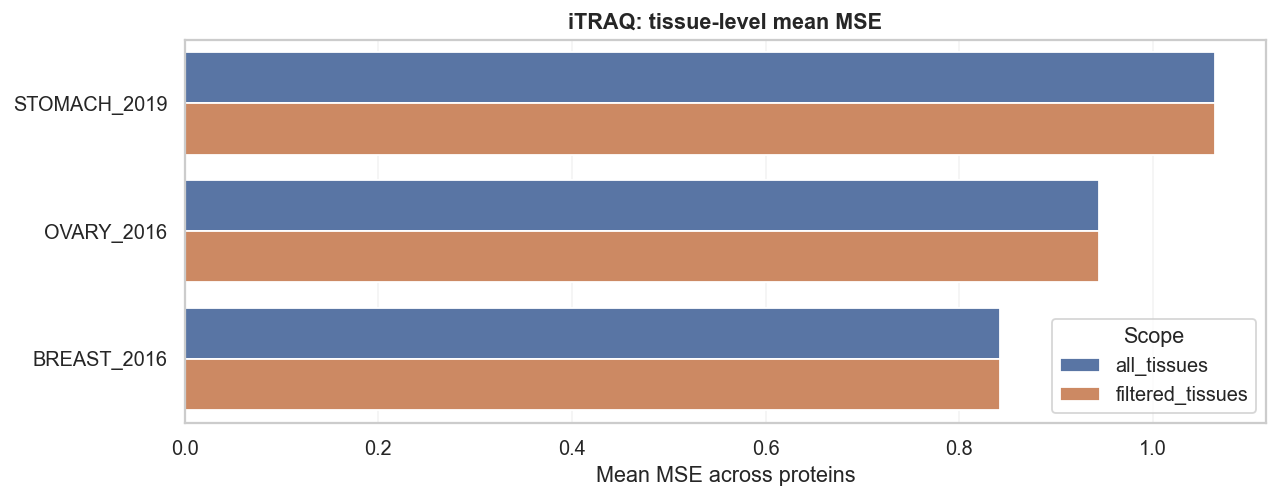

In [9]:
tissue_rows = []
for (dataset, scope), bundle in cptac_results.items():
    tdf = bundle["tissue_df"].copy()
    if len(tdf):
        tissue_rows.append(tdf)

tissue_mse_df = pd.concat(tissue_rows, ignore_index=True) if tissue_rows else pd.DataFrame()
plot_cptac_tissue_mse(tissue_mse_df)

## 6. Top and bottom proteins

A concise table replaces the repeated per-dataset top-list cells from the original notebooks.

In [10]:
if len(long_results_df):
    top_corr = (
        long_results_df.dropna(subset=["Correlation"])
        .sort_values(["Dataset", "Scope", "Correlation"], ascending=[True, True, False])
        .groupby(["Dataset", "Scope"], as_index=False)
        .head(10)
    )
    best_mse = (
        long_results_df.dropna(subset=["MSE"])
        .sort_values(["Dataset", "Scope", "MSE"], ascending=[True, True, True])
        .groupby(["Dataset", "Scope"], as_index=False)
        .head(10)
    )
    print("Top 10 proteins by correlation per dataset/scope")
    display(top_corr[["Dataset", "Scope", "Protein", "Correlation", "MSE", "Cosine_Similarity"]].round(4))
    print("Top 10 proteins by lowest MSE per dataset/scope")
    display(best_mse[["Dataset", "Scope", "Protein", "MSE", "Correlation", "Cosine_Similarity"]].round(4))

Top 10 proteins by correlation per dataset/scope


,Dataset,Scope,Protein,Correlation,MSE,Cosine_Similarity
379,LabelFree,all_tissues,AGR2,0.8172,5.8059,0.8409
463,LabelFree,all_tissues,KLC1,0.8079,0.3435,0.8065
471,LabelFree,all_tissues,MAP1B,0.7679,1.0937,0.7591
488,LabelFree,all_tissues,PEBP1,0.7506,0.1662,0.7513
404,LabelFree,all_tissues,COL12A1,0.7486,0.3917,0.7606
392,LabelFree,all_tissues,CAMK2G,0.7458,0.2801,0.7458
403,LabelFree,all_tissues,CNP,0.7388,0.6923,0.7308
548,LabelFree,all_tissues,TXNRD1,0.7191,0.3282,0.7202
412,LabelFree,all_tissues,COPS6,0.6974,1.5068,0.6930
380,LabelFree,all_tissues,AHSA1,0.6635,0.4819,0.6618


Top 10 proteins by lowest MSE per dataset/scope


,Dataset,Scope,Protein,MSE,Correlation,Cosine_Similarity
488,LabelFree,all_tissues,PEBP1,0.1662,0.7506,0.7513
394,LabelFree,all_tissues,CAV1,0.2298,0.6244,0.5973
494,LabelFree,all_tissues,PPA2,0.2800,0.5162,0.5092
392,LabelFree,all_tissues,CAMK2G,0.2801,0.7458,0.7458
548,LabelFree,all_tissues,TXNRD1,0.3282,0.7191,0.7202
375,LabelFree,all_tissues,ACSF2,0.3330,0.6396,0.6401
463,LabelFree,all_tissues,KLC1,0.3435,0.8079,0.8065
396,LabelFree,all_tissues,CDH1,0.3468,0.5368,0.6366
404,LabelFree,all_tissues,COL12A1,0.3917,0.7486,0.7606
497,LabelFree,all_tissues,PRDX3,0.3950,0.1775,0.1768


## 7. Optional exports

In [11]:
SAVE_TABLES = False
if SAVE_TABLES:
    summary_df.to_csv(OUTPUT_DIR / "cptac_summary.csv", index=False)
    long_results_df.to_csv(OUTPUT_DIR / "cptac_protein_results.csv", index=False)
    tissue_mse_df.to_csv(OUTPUT_DIR / "cptac_tissue_mse.csv", index=False)
    coverage_df.to_csv(OUTPUT_DIR / "cptac_feature_coverage.csv", index=False)
    print("Saved tables to", OUTPUT_DIR.resolve())